In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

In [2]:
df = pd.read_csv("data/vital_signs_dataset.csv") 
df.head()

,patient_id,bpm,spo2,temperature,systolic_bp,diastolic_bp,respiratory_rate,risk_level
0,P1000,87,97.9,36.5,133,69,11,0
1,P1001,140,91.2,38.1,147,90,30,2
2,P1002,90,92.3,36.8,138,76,25,1
3,P1003,82,97.8,36.5,112,78,15,0
4,P1004,82,97.7,36.9,117,79,15,0


In [3]:
# features
features = ['bpm', 'spo2', 'temperature']
X = df[features]
X.head

<bound method NDFrame.head of       bpm   spo2  temperature
0      87   97.9         36.5
1     140   91.2         38.1
2      90   92.3         36.8
3      82   97.8         36.5
4      82   97.7         36.9
...   ...    ...          ...
1195   87   93.4         37.1
1196  127   93.0         38.1
1197  135   91.7         36.4
1198   98   93.8         36.2
1199   67  100.0         36.8

[1200 rows x 3 columns]>

In [4]:
y = df['risk_level']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=42)

In [6]:
model = RandomForestClassifier(random_state=42, n_estimators=100)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
acc = accuracy_score(y_test, predictions) 
print(f"Précision globale : {acc * 100:.2f}%")

Précision globale : 100.00%


In [7]:
model.score(X_test, y_test)

print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       170
           1       1.00      1.00      1.00        45
           2       1.00      1.00      1.00        25

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



<Figure size 700x500 with 0 Axes>

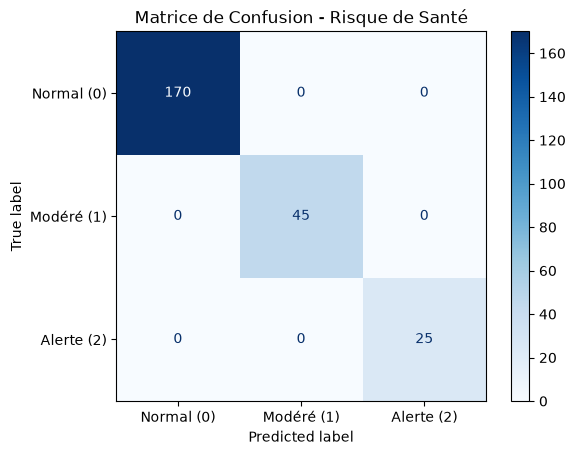

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
# Affichage de la matrice de confusion 
plt.figure(figsize=(7, 5)) 
ConfusionMatrixDisplay.from_predictions( y_test, predictions, display_labels=['Normal (0)', 'Modéré (1)', 'Alerte (2)'], cmap=plt.cm.Blues )
plt.title("Matrice de Confusion - Risque de Santé") 
plt.grid(False)
plt.show()

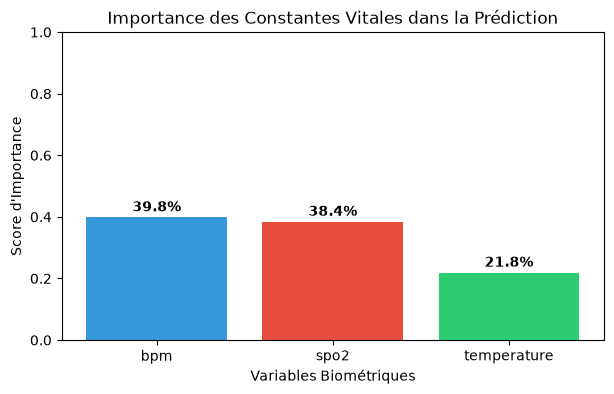

In [9]:
# Extraction de l'importance des variables
importances = model.feature_importances_

plt.figure(figsize=(7, 4))
plt.bar(features, importances, color=['#3498db', '#e74c3c', '#2ecc71'])
plt.title("Importance des Constantes Vitales dans la Prédiction")
plt.xlabel("Variables Biométriques")
plt.ylabel("Score d'Importance")
plt.ylim(0, 1)

# Affichage des valeurs au-dessus des barres
for i, v in enumerate(importances):
    plt.text(i, v + 0.02, f"{v*100:.1f}%", ha='center', fontweight='bold')

plt.show()


In [10]:

import joblib

# Sauvegarde du modèle entraîné dans le sous-dossier ml/
joblib.dump(model, 'first_model.joblib')
print("✅ Modèle sauvegardé avec succès sous 'ml/model.joblib' !")

#ttest du model
# Chargement  modèle depuis le fichier .joblib
loaded_model = joblib.load('first_model.joblib')

# Tester une prédiction à chaud : BPM = 120, SpO2 = 90%, Temp = 38.8°C (Cas Alerte / 2)
test_patient = [[120, 90.0, 38.8]]
prediction_test = loaded_model.predict(test_patient)
proba_test = loaded_model.predict_proba(test_patient)

print(f"Classe prédite : {prediction_test[0]}") 
print(f"Probabilités par classe [Normal, Modéré, Alerte] : {proba_test[0]}")


✅ Modèle sauvegardé avec succès sous 'ml/model.joblib' !
Classe prédite : 2
Probabilités par classe [Normal, Modéré, Alerte] : [0. 0. 1.]


/home/chrys_hcr/workspace/EcoHealth-Predict/backend/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/home/chrys_hcr/workspace/EcoHealth-Predict/backend/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
